# Superstore Sales & Profitability Analysis | Python

**Business question:** Which categories, regions, and customer segments drive sales and profit, and where should the business investigate losses?

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn. Data source: `Sample - Superstore.xlsx` (Orders sheet).

### 1. Import and understand the data ###

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read the Orders sheet from the Excel file
df = pd.read_excel("Sample - Superstore.xlsx", sheet_name="Orders")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [3]:
df.shape

(10194, 21)

In [4]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [6]:
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


**Data quality note:** The Orders sheet contains 10,194 rows, with no missing values or exact duplicate rows in the original file. We inspect sales outliers rather than deleting them automatically because large orders may be valid.

### 2. Data Cleaning ###

In [7]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
# Check text columns before cleaning
text_columns = df.select_dtypes(include="object").columns
print("Text columns:", list(text_columns))

Text columns: ['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']


C:\Users\amrad\AppData\Local\Temp\ipykernel_13280\4014835905.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


### outlier

In [10]:
Q1 = df["Sales"].quantile(0.25)
Q3= df["Sales"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

sales_outliers = df [
    (df["Sales"] < lower_bound) |
    (df["Sales"] > upper_bound)
]

sales_outliers.shape

(1183, 21)

In [11]:
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Sales Outliers:", len(sales_outliers))

# in sales if there is one large deal it is normal and could happen so i will leave it

Lower Bound: -271.20000000000005
Upper Bound: 497.92
Number of Sales Outliers: 1183


### feature engineering

In [12]:
df["Profit Margin"] = (df["Profit"] / df["Sales"]) * 100

In [13]:
df["Shipping Duration"] = (df["Ship Date"] - df["Order Date"]).dt.days

In [14]:
def sales_category(sales):
    if sales < 100:
        return "Low"
    elif sales < 500:
        return "Medium"
    else:
        return "High"

df["Sales Performance Category"] = df["Sales"].apply(sales_category)

In [15]:
df[
    ["Sales", "Profit", "Profit Margin",
     "Shipping Duration", "Sales Performance Category"]
].head()

,Sales,Profit,Profit Margin,Shipping Duration,Sales Performance Category
0,16.448,5.5512,33.75,4,Low
1,3.540,-5.4870,-155.00,4,Low
2,11.784,4.2717,36.25,4,Low
3,272.736,-64.7748,-23.75,4,Medium
4,19.536,4.8840,25.00,7,Low


### reusable preprocessing pipelines

In [16]:
class DataCleaner:
    def __init__(self, data):
        self.data = data.copy()

    def clean(self):
        self.data = self.data.drop_duplicates()
        for col in self.data.select_dtypes(include="object").columns:
            self.data[col] = self.data[col].str.strip()
        return self.data


In [17]:
cleaner = DataCleaner(df)
clean_df = cleaner.clean()
print("Rows after cleaning:", len(clean_df))

# Use the cleaned dataset in the rest of the analysis
df = clean_df.copy()


Rows after cleaning: 10194


C:\Users\amrad\AppData\Local\Temp\ipykernel_13280\292981558.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in self.data.select_dtypes(include="object").columns:


## exploratory data analysis

 Total Sales by category

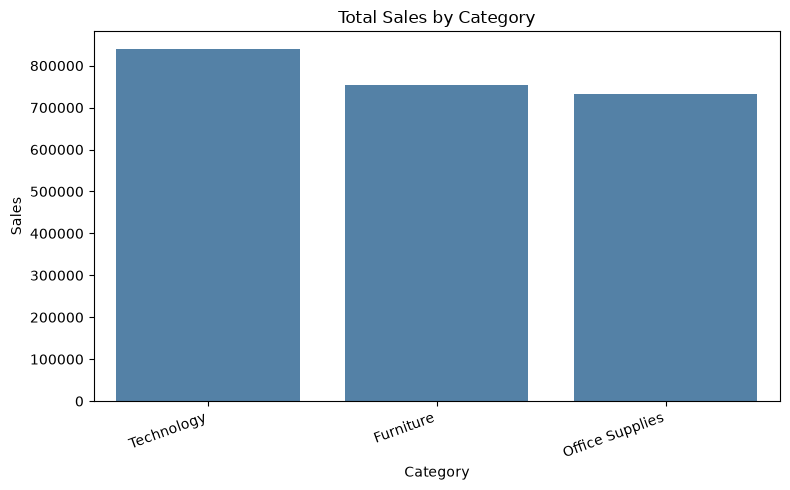

In [18]:
summary = df.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=summary, x="Category", y="Sales", color="steelblue")
plt.title("Total Sales by Category")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Total profit by category

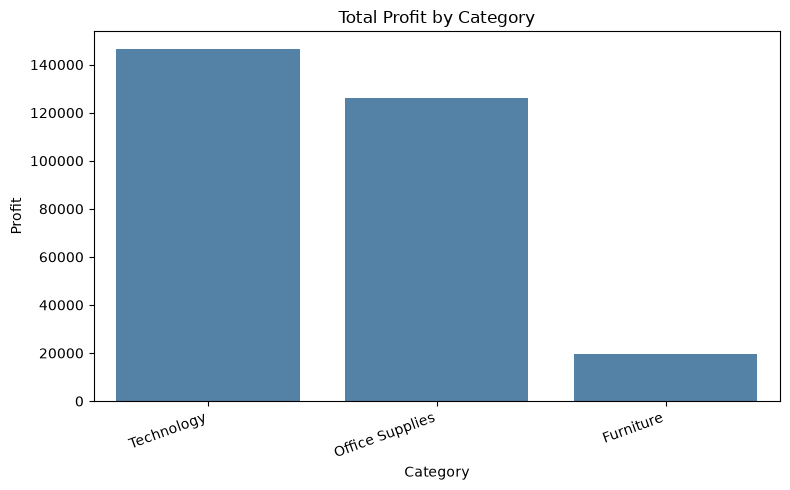

In [19]:
summary = df.groupby("Category", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=summary, x="Category", y="Profit", color="steelblue")
plt.title("Total Profit by Category")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Sales by region

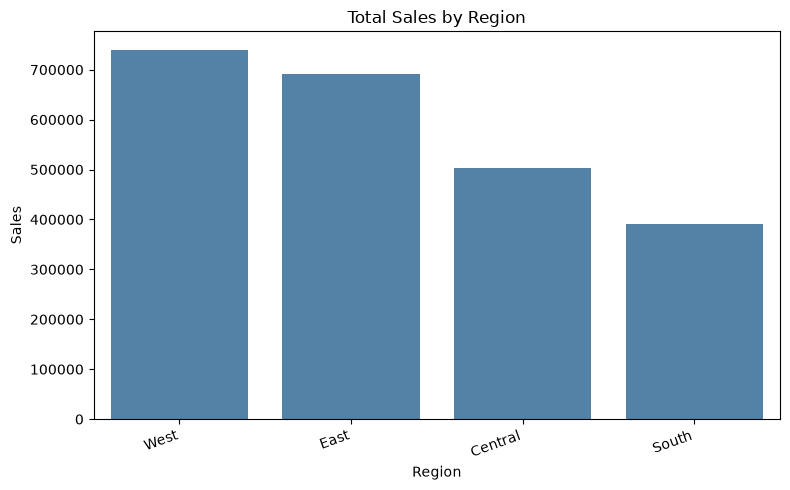

In [20]:
summary = df.groupby("Region", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=summary, x="Region", y="Sales", color="steelblue")
plt.title("Total Sales by Region")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Sales over time

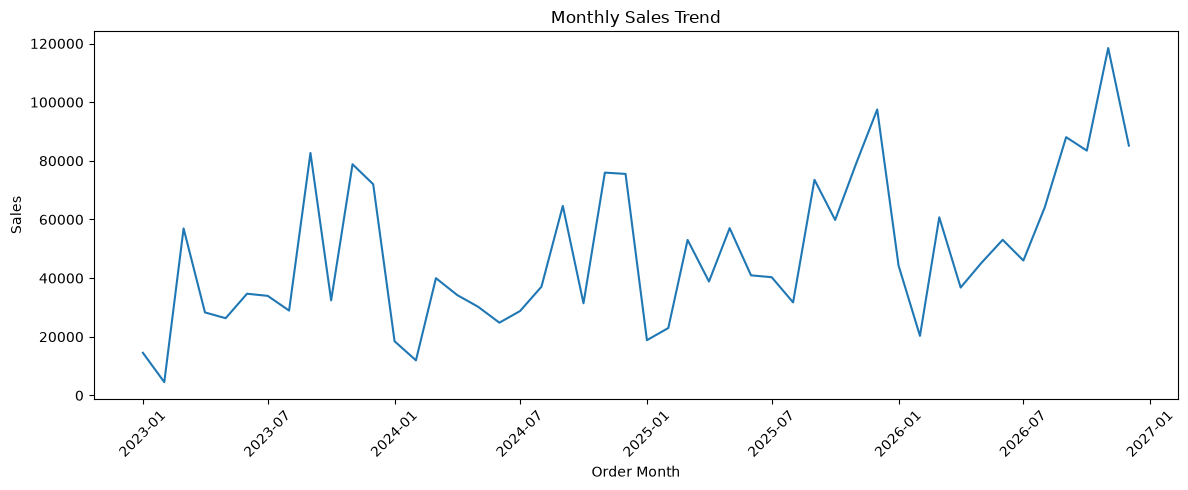

In [21]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Sales vs Profit

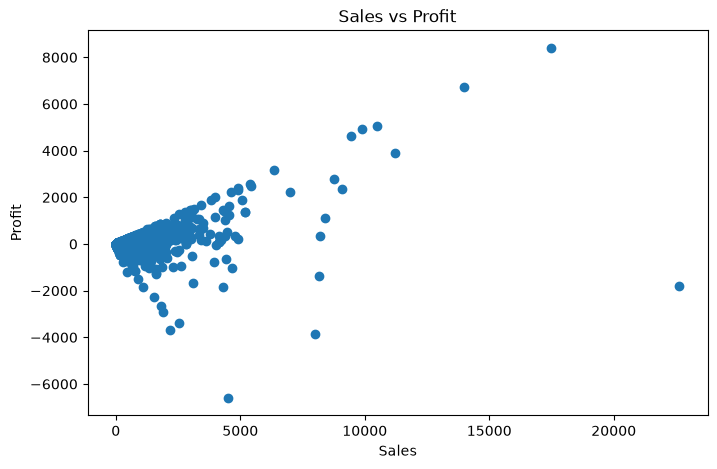

In [22]:
plt.figure(figsize=(8,5))

plt.scatter(df["Sales"], df["Profit"])

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

Sales by segment

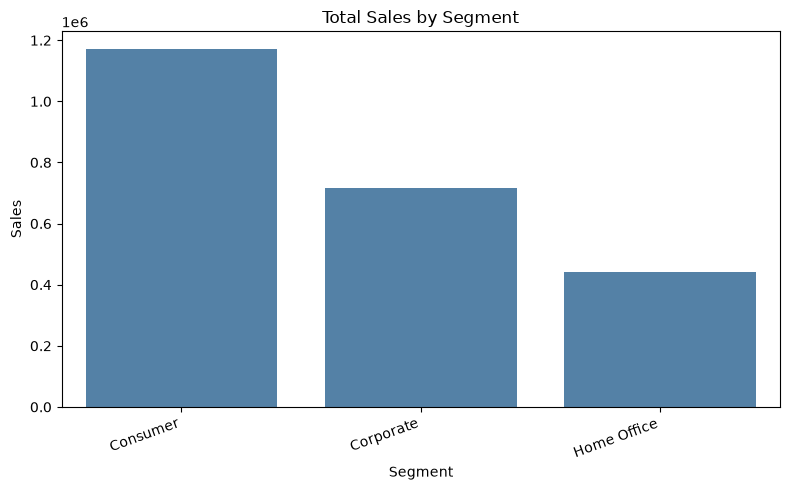

In [23]:
summary = df.groupby("Segment", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=summary, x="Segment", y="Sales", color="steelblue")
plt.title("Total Sales by Segment")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Total profit by sub-category

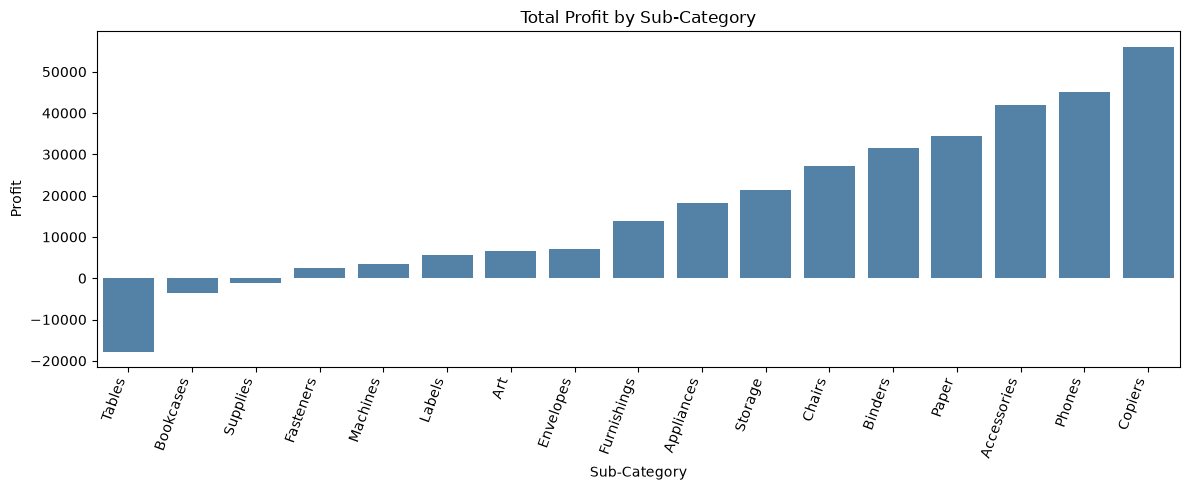

In [24]:
summary = df.groupby("Sub-Category", as_index=False)["Profit"].sum().sort_values("Profit", ascending=True)
plt.figure(figsize=(12, 5))
sns.barplot(data=summary, x="Sub-Category", y="Profit", color="steelblue")
plt.title("Total Profit by Sub-Category")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

Discount vs Profit

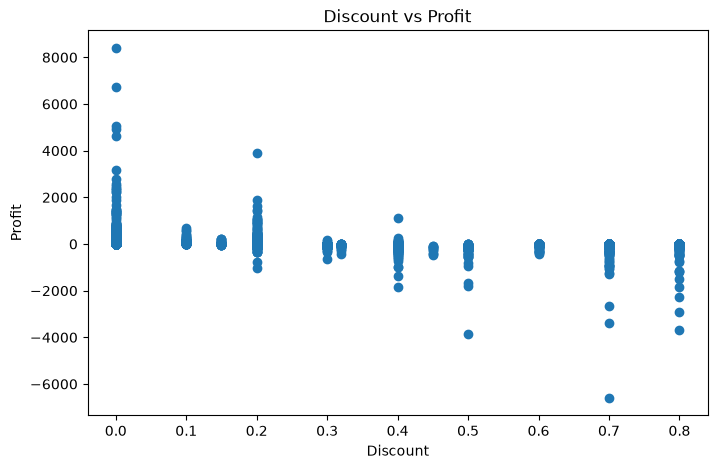

In [25]:
plt.figure(figsize=(8,5))

plt.scatter(df["Discount"], df["Profit"])

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

## Correlation Analysis

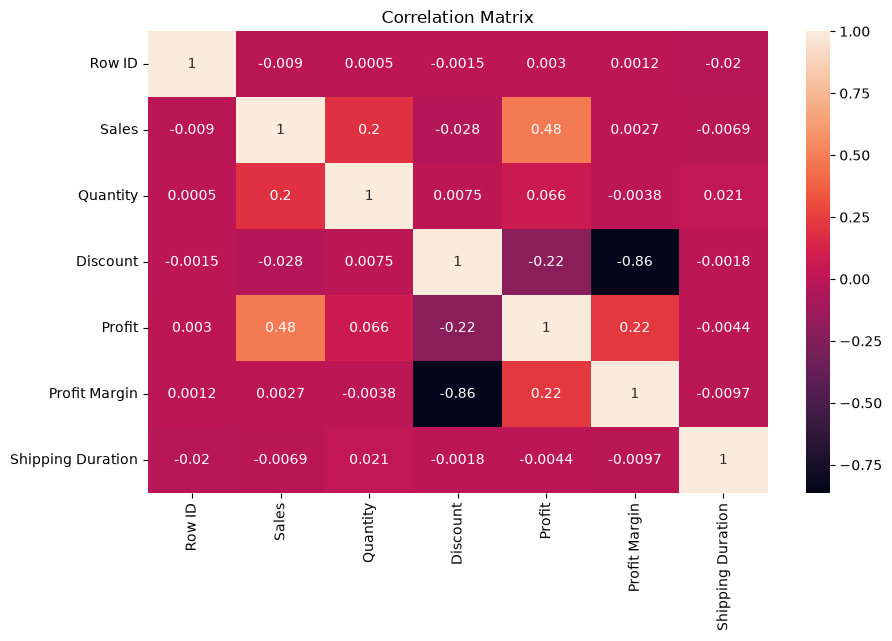

In [26]:
num_data = df.select_dtypes(include="number")
corr = num_data.corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True)

plt.title("Correlation Matrix")
plt.show()

## Distribution analysis

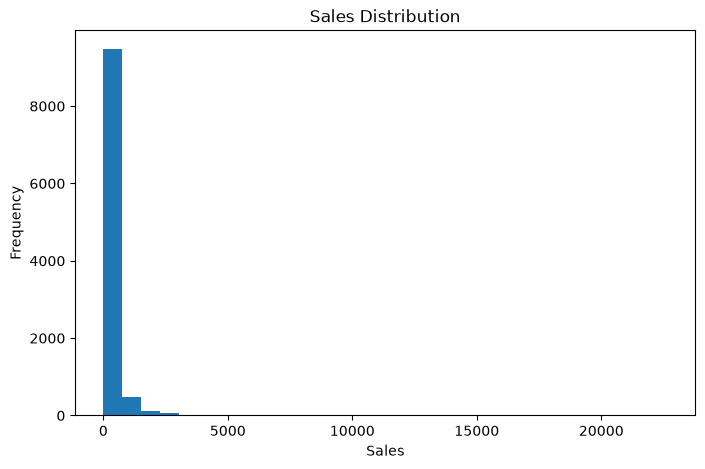

In [27]:
plt.figure(figsize=(8,5))

plt.hist(df["Sales"], bins=30)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

## Memory usage

In [28]:
memory_before = df.memory_usage(deep=True).sum()

for col in ["Category", "Segment", "Region", "Ship Mode"]:
    df[col] = df[col].astype("category")

memory_after = df.memory_usage(deep=True).sum()

print("Memory before:", memory_before)
print("Memory after:", memory_after)

Memory before: 9794227
Memory after: 7437069


The correlation matrix helps us compare numeric variables. Correlation does not prove that one variable causes another. In this dataset, discounts have a negative relationship with profit, which is worth investigating by category and product.

### Key Findings

- Technology has the highest category sales ($839,893.28) and profit ($146,543.38).
- The West region has the highest sales ($739,813.61).
- Consumer has the highest segment sales ($1,170,659.79).
- Tables (-$17,753.21), Bookcases (-$3,632.07), and Supplies (-$1,171.39) have negative total profit.
- Discounts and profit have a negative correlation (about -0.22), but this alone does not establish causation.

### Conclusion

Total sales are strong, but profitability varies across product categories. Furniture generates substantial sales while contributing much less profit than Technology or Office Supplies. I would review discounting and product costs for loss-making sub-categories before recommending pricing changes.

### Automated KPI Summary

In [29]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
average_sales = df["Sales"].mean()
average_profit = df["Profit"].mean()
profit_margin = (total_profit / total_sales) * 100

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Sales per Row: ${average_sales:,.2f}")
print(f"Average Profit per Row: ${average_profit:,.2f}")

Total Sales: $2,326,534.35
Total Profit: $292,296.81
Profit Margin: 12.56%
Average Sales per Row: $228.23
Average Profit per Row: $28.67


### Automated Analytical Summary

In [30]:
top_category = df.groupby("Category")["Sales"].sum().idxmax()
top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_segment = df.groupby("Segment")["Sales"].sum().idxmax()

print("Top Sales Category:", top_category)
print("Top Sales Region:", top_region)
print("Top Sales Segment:", top_segment)

Top Sales Category: Technology
Top Sales Region: West
Top Sales Segment: Consumer


### Export Cleaned Data

In [31]:
df.to_csv("cleaned_superstore.csv", index=False)
print("Cleaned data exported successfully.")

Cleaned data exported successfully.


### Final Summary

I cleaned and analyzed 10,194 Superstore order lines using Python. Total sales were $2,326,534.35 and total profit was $292,296.81, giving a 12.56% profit margin. The main opportunity is to investigate low-profit furniture products and discounting while protecting strong-performing categories.